In [4]:
from pandas import read_sql

from postgre_tools import Users, create_postgres_engine


In [5]:
engine = create_postgres_engine(Users.AIRBNB.load_user())

# Set count to None if you want to fetch all rows
listings_row_count: int | None = None
amenities_row_count: int | None = None

if listings_row_count is not None and listings_row_count <= 0:
    raise ValueError("listings_row_count must be greater than 0")
if amenities_row_count is not None and amenities_row_count <= 0:
    raise ValueError("amenities_row_count must be greater than 0")

listings_query = "SELECT * FROM listings"
amenities_query = "SELECT * FROM listing_amenities"

if listings_row_count is not None:
    listings_query += f" LIMIT {listings_row_count}"

if amenities_row_count is not None:
    amenities_query += f" LIMIT {amenities_row_count}"

listings_df = read_sql(listings_query, engine)
listing_amenities_df = read_sql(amenities_query, engine)

engine.dispose()

In [6]:
print("=== LISTINGS DATASET ===")
print(f"Number of rows: {len(listings_df):,}")
print(f"Number of columns: {len(listings_df.columns)}")

print("\n=== AVAILABLE FEATURES ===")
print(listings_df.dtypes.to_string())

print("\n=== AMENITIES DATASET ===")
print(f"Number of rows: {len(listing_amenities_df):,}")
print(f"Number of columns: {len(listing_amenities_df.columns)}")

print("\n=== AMENITIES FEATURES ===")
print(listing_amenities_df.dtypes.to_string())

=== LISTINGS DATASET ===
Number of rows: 4,806
Number of columns: 36

=== AVAILABLE FEATURES ===
id                               int64
host_id                          int64
listing_url                        str
picture_url                        str
latitude                       float64
longitude                      float64
property_type                      str
room_type                          str
accommodates                     int64
bedrooms                       float64
beds                           float64
bathrooms                      float64
bathrooms_text                     str
price                          float64
minimum_nights                   int64
maximum_nights                   int64
availability_30                  int64
availability_60                  int64
availability_90                  int64
availability_365                 int64
number_of_reviews                int64
number_of_reviews_ltm            int64
number_of_reviews_l30d           int64
first_

In [7]:
import pandas as pd

print("=== PRICE STATISTICS ===")

price = listings_df["price"]

print(f"Total listings: {len(price):,}")
print(f"Missing prices: {price.isna().sum():,}")
print(f"Missing percentage: {price.isna().mean() * 100:.2f}%")

print(f"\nZero prices: {(price == 0).sum():,}")
print(f"Negative prices: {(price < 0).sum():,}")

print("\n=== PRICE DISTRIBUTION ===")
print(price.describe(percentiles=[
    0.01, 0.05, 0.10, 0.25,
    0.50, 0.75, 0.90, 0.95, 0.99
]).to_string())

print("\n=== MOST EXPENSIVE LISTINGS ===")
print(
    listings_df[
        ["id", "price", "room_type", "accommodates", "bedrooms"]
    ]
    .sort_values("price", ascending=False)
    .head(10)
    .to_string(index=False)
)

=== PRICE STATISTICS ===
Total listings: 4,806
Missing prices: 1,542
Missing percentage: 32.08%

Zero prices: 0
Negative prices: 0

=== PRICE DISTRIBUTION ===
count     3264.000000
mean      2388.138906
std       2101.199397
min         32.470000
1%         256.407100
5%         475.300000
10%        667.713000
25%       1141.330000
50%       1940.000000
75%       3083.250000
90%       4490.493000
95%       5550.500000
99%       9149.980000
max      40000.000000

=== MOST EXPENSIVE LISTINGS ===
                 id    price       room_type  accommodates  bedrooms
 920900355178934780 40000.00 Entire home/apt             6       2.0
1617201210178577353 30000.00 Entire home/apt            13       6.0
           54126655 25998.00    Private room            16      12.0
 599723488406885421 25995.00 Entire home/apt            16      12.0
 749651285872917342 25714.29 Entire home/apt             6       4.0
 599691967730847088 22995.00 Entire home/apt            16      12.0
 6751520697096189

In [8]:
from sqlalchemy import inspect

inspector = inspect(engine)

print("=== AVAILABLE DATABASE TABLES ===")
for table in inspector.get_table_names():
    print(table)

print("\n=== CALENDAR-RELATED TABLES ===")
calendar_tables = [
    table for table in inspector.get_table_names()
    if "calendar" in table.lower()
]

if calendar_tables:
    for table in calendar_tables:
        print(f"\nTable: {table}")
        for column in inspector.get_columns(table):
            print(f"  {column['name']}: {column['type']}")
else:
    print("No calendar-related tables found.")

=== AVAILABLE DATABASE TABLES ===
apartment_sales
tourism_attractions
listings
listing_amenities
listing_reviews
listing_calendar

=== CALENDAR-RELATED TABLES ===

Table: listing_calendar
  listing_id: BIGINT
  date: DATE
  available: CHAR(1)


In [9]:
# Proposed features for Airbnb price prediction
candidate_features = [
    "room_type",
    "property_type",
    "accommodates",
    "bedrooms",
    "beds",
    "bathrooms",
    "latitude",
    "longitude",
]

# Only include features that actually exist
available_features = [
    col for col in candidate_features
    if col in listings_df.columns
]

# Keep listings with a known, positive nightly price
priced_df = listings_df[
    listings_df["price"].notna() &
    (listings_df["price"] > 0)
].copy()

print("=== DATASET AFTER PRICE FILTERING ===")
print(f"Listings: {len(priced_df):,}")

print("\n=== MISSING FEATURE VALUES ===")

missing_summary = pd.DataFrame({
    "Missing count": priced_df[available_features].isna().sum(),
    "Missing %": (
        priced_df[available_features].isna().mean() * 100
    ).round(2),
    "Unique values": priced_df[available_features].nunique()
})

print(missing_summary.to_string())

print("\n=== CATEGORICAL FEATURES ===")

for col in ["room_type", "property_type"]:
    if col in priced_df.columns:
        print(f"\n{col}:")
        print(priced_df[col].value_counts(dropna=False).to_string())

=== DATASET AFTER PRICE FILTERING ===
Listings: 3,264

=== MISSING FEATURE VALUES ===
               Missing count  Missing %  Unique values
room_type                  0       0.00              3
property_type              0       0.00             41
accommodates               0       0.00             16
bedrooms                 484      14.83             10
beds                     441      13.51             16
bathrooms                564      17.28             12
latitude                   0       0.00           2850
longitude                  0       0.00           3035

=== CATEGORICAL FEATURES ===

room_type:
room_type
Entire home/apt    2634
Private room        604
Shared room          26

property_type:
property_type
Entire rental unit                    1729
Entire home                            430
Private room in rental unit            364
Entire condo                           178
Entire villa                           102
Room in hotel                           55
Entire 

In [10]:
import pandas as pd

print("=== PRICE BY ROOM TYPE ===")

room_summary = (
    priced_df
    .groupby("room_type")["price"]
    .agg(["count", "median", "mean", "std"])
    .round(2)
    .sort_values("median", ascending=False)
)

print(room_summary.to_string())

print("\n=== TOP 15 PROPERTY TYPES ===")

property_summary = (
    priced_df
    .groupby("property_type")["price"]
    .agg(["count", "median", "mean"])
    .round(2)
    .sort_values("count", ascending=False)
)

print(property_summary.head(15).to_string())

print("\n=== PRICE BY ACCOMMODATION CAPACITY ===")

capacity_summary = (
    priced_df
    .groupby("accommodates")["price"]
    .agg(["count", "median", "mean"])
    .round(2)
    .sort_index()
)

print(capacity_summary.to_string())

=== PRICE BY ROOM TYPE ===
                 count   median     mean      std
room_type                                        
Entire home/apt   2634  2276.65  2707.97  2123.62
Private room       604   837.80  1071.73  1365.73
Shared room         26   362.50   567.64   446.30

=== TOP 15 PROPERTY TYPES ===
                                   count   median     mean
property_type                                             
Entire rental unit                  1729  2016.00  2407.35
Entire home                          430  3168.25  3615.11
Private room in rental unit          364   726.84   858.30
Entire condo                         178  2232.38  2704.83
Entire villa                         102  3631.90  4080.65
Room in hotel                         55  1264.00  2128.28
Entire townhouse                      47  2594.33  2718.87
Private room in home                  43   570.00   901.89
Private room in condo                 33   856.00  1155.25
Private room in hostel                33  1

In [11]:
print("=== AMENITIES DATASET ===")

print(f"Total amenity records: {len(listing_amenities_df):,}")
print(f"Unique listings: {listing_amenities_df['listing_id'].nunique():,}")
print(f"Unique amenities: {listing_amenities_df['amenity'].nunique():,}")

print("\n=== TOP 30 MOST COMMON AMENITIES ===")

amenity_counts = (
    listing_amenities_df
    .groupby("amenity")["listing_id"]
    .nunique()
    .sort_values(ascending=False)
)

print(amenity_counts.head(30).to_string())

print("\n=== AMENITIES PER LISTING ===")

amenities_per_listing = (
    listing_amenities_df
    .groupby("listing_id")["amenity"]
    .nunique()
)

print(amenities_per_listing.describe().to_string())

print("\n=== LISTING COVERAGE ===")

priced_ids = set(priced_df["id"])
amenity_ids = set(listing_amenities_df["listing_id"])

matched_ids = priced_ids.intersection(amenity_ids)

print(f"Priced listings: {len(priced_ids):,}")
print(f"Priced listings with amenity records: {len(matched_ids):,}")
print(f"Priced listings without amenity records: {len(priced_ids - amenity_ids):,}")

=== AMENITIES DATASET ===
Total amenity records: 103,363
Unique listings: 4,804
Unique amenities: 50

=== TOP 30 MOST COMMON AMENITIES ===


amenity
Kitchen                       4560
Wifi                          4377
Smoke alarm                   4234
Hot water                     3446
Dishes and silverware         3154
TV                            3005
Bed linens                    2963
Refrigerator                  2908
Hangers                       2897
Cooking basics                2872
Iron                          2763
Hair dryer                    2732
Essentials                    2712
Fire extinguisher             2639
Washer                        2522
Microwave                     2420
Freezer                       2336
Dishwasher                    2333
Dining table                  2323
Wine glasses                  2248
Heating                       2230
Dedicated workspace           2168
Oven                          2003
Room-darkening shades         1918
Shampoo                       1908
Hot water kettle              1835
Extra pillows and blankets    1801
Cleaning products             1767
Self check-i

=== AMENITY COUNT AND PRICE ===
               amenity_count  price
amenity_count          1.000  0.329
price                  0.329  1.000

=== PRICE BY AMENITY COUNT ===
               count  median     mean
amenity_group                        
1–10             705  1376.0  1852.12
11–20            671  1655.0  2109.53
21–30           1039  1863.0  2324.35
31–40            802  2742.0  3110.57
41–50             46  3684.0  3554.73


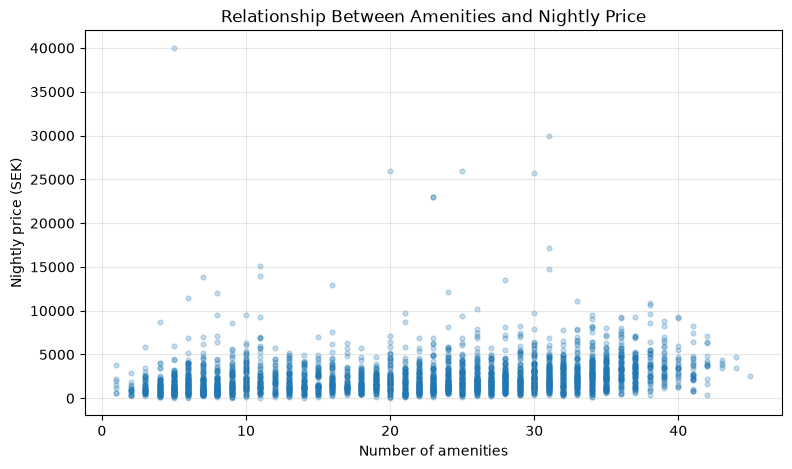

In [12]:
import matplotlib.pyplot as plt

# Count unique amenities per listing
amenity_counts = (
    listing_amenities_df
    .groupby("listing_id")["amenity"]
    .nunique()
    .rename("amenity_count")
)

# Join counts to listings with valid prices
amenity_analysis_df = priced_df[
    ["id", "price", "room_type", "accommodates"]
].merge(
    amenity_counts,
    left_on="id",
    right_index=True,
    how="left"
)

print("=== AMENITY COUNT AND PRICE ===")

print(
    amenity_analysis_df[
        ["amenity_count", "price"]
    ]
    .corr(method="spearman")
    .round(3)
)

print("\n=== PRICE BY AMENITY COUNT ===")

amenity_analysis_df["amenity_group"] = pd.cut(
    amenity_analysis_df["amenity_count"],
    bins=[0, 10, 20, 30, 40, 50],
    labels=["1–10", "11–20", "21–30", "31–40", "41–50"]
)

summary = (
    amenity_analysis_df
    .groupby("amenity_group", observed=True)["price"]
    .agg(["count", "median", "mean"])
    .round(2)
)

print(summary.to_string())

# Visualization
plt.figure(figsize=(9, 5))

plt.scatter(
    amenity_analysis_df["amenity_count"],
    amenity_analysis_df["price"],
    alpha=0.25,
    s=12
)

plt.xlabel("Number of amenities")
plt.ylabel("Nightly price (SEK)")
plt.title("Relationship Between Amenities and Nightly Price")
plt.grid(alpha=0.3)
plt.show()

In [13]:
from sklearn.model_selection import train_test_split

# Features selected for the initial baseline
numeric_features = [
    "accommodates",
    "bedrooms",
    "beds",
    "bathrooms",
    "latitude",
    "longitude",
    "amenity_count"
]

categorical_features = [
    "room_type",
    "property_type"
]

# Create dataset with amenity counts
model_df = priced_df.merge(
    amenity_counts,
    left_on="id",
    right_index=True,
    how="left"
)

# Keep missing amenity counts as NaN for now.
# We will handle them inside the preprocessing pipeline.

feature_columns = numeric_features + categorical_features

X = model_df[feature_columns].copy()
y = model_df["price"].copy()

# Split listings into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("=== DATASET SPLIT ===")
print(f"Training samples: {len(X_train):,}")
print(f"Testing samples: {len(X_test):,}")

print("\n=== INPUT FEATURES ===")
print(X.columns.tolist())

print("\n=== TRAINING TARGET STATISTICS ===")
print(y_train.describe().round(2).to_string())

print("\n=== TEST TARGET STATISTICS ===")
print(y_test.describe().round(2).to_string())

=== DATASET SPLIT ===
Training samples: 2,611
Testing samples: 653

=== INPUT FEATURES ===
['accommodates', 'bedrooms', 'beds', 'bathrooms', 'latitude', 'longitude', 'amenity_count', 'room_type', 'property_type']

=== TRAINING TARGET STATISTICS ===
count     2611.00
mean      2392.35
std       2125.52
min         32.47
25%       1141.33
50%       1940.14
75%       3106.75
max      40000.00

=== TEST TARGET STATISTICS ===
count      653.00
mean      2371.29
std       2002.47
min        111.36
25%       1142.00
50%       1853.00
75%       2990.00
max      25714.29


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        min_frequency=10,
        sparse_output=False
    ))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    verbose_feature_names_out=False
)

print("=== PREPROCESSING PIPELINE ===")
print(preprocessor)

=== PREPROCESSING PIPELINE ===
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(add_indicator=True,
                                                                strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['accommodates', 'bedrooms', 'beds',
                                  'bathrooms', 'latitude', 'longitude',
                                  'amenity_count']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                min

In [15]:
import mlflow

from mlflow_utils import load_config, test_server_connection

# Load the existing project's MLflow configuration
load_config()

# Verify connection to the tracking server
test_server_connection()

print("\nTracking URI:", mlflow.get_tracking_uri())

c:\Users\Kim\software engineering\year 5\LP1\4DT911\4dt911-vis-project-research\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Configuration loaded successfully.
MLflow connection successful!
Found 1 experiment(s)

Tracking URI: https://cu0089.camp.lnu.se/mlflow/


In [16]:
import numpy as np

from sklearn.dummy import DummyRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

# Define baseline model with preprocessing
baseline_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DummyRegressor(strategy="median"))
])

# Metrics for cross-validation
scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2"
}

# Configure experiment on the remote MLflow server
mlflow.set_experiment("airbnb-price-prediction")

with mlflow.start_run(run_name="baseline-dummy-median") as run:

    # Perform 5-fold cross-validation
    cv_results = cross_validate(
        baseline_pipeline,
        X_train,
        y_train,
        cv=5,
        scoring=scoring
    )

    # Average metrics across folds
    cv_mae = -cv_results["test_mae"].mean()
    cv_rmse = -cv_results["test_rmse"].mean()
    cv_r2 = cv_results["test_r2"].mean()

    # Log parameters
    mlflow.log_params({
        "model": "DummyRegressor",
        "strategy": "median",
        "cv_folds": 5,
        "training_samples": len(X_train),
        "feature_count": X_train.shape[1]
    })

    # Log metrics
    mlflow.log_metrics({
        "cv_mae": cv_mae,
        "cv_rmse": cv_rmse,
        "cv_r2": cv_r2
    })

    print("=== BASELINE MODEL (5-FOLD CV) ===")
    print(f"MAE:  {cv_mae:.2f} SEK")
    print(f"RMSE: {cv_rmse:.2f} SEK")
    print(f"R²:   {cv_r2:.4f}")

    print(f"\nMLflow Run ID: {run.info.run_id}")

# Fit baseline on all training data
baseline_pipeline.fit(X_train, y_train)

print("\nBaseline model fitted successfully.")

=== BASELINE MODEL (5-FOLD CV) ===
MAE:  1274.67 SEK
RMSE: 2146.46 SEK
R²:   -0.0443

MLflow Run ID: a72a358288e544ee80e1307b8a9d1f95
🏃 View run baseline-dummy-median at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2/runs/a72a358288e544ee80e1307b8a9d1f95
🧪 View experiment at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2

Baseline model fitted successfully.


In [17]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

import mlflow
import numpy as np

# Build Ridge Regression pipeline
ridge_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=1.0))
])

# Track experiment in MLflow
with mlflow.start_run(run_name="ridge-regression") as run:

    cv_results = cross_validate(
        ridge_pipeline,
        X_train,
        y_train,
        cv=5,
        scoring=scoring
    )

    cv_mae = -cv_results["test_mae"].mean()
    cv_rmse = -cv_results["test_rmse"].mean()
    cv_r2 = cv_results["test_r2"].mean()

    mlflow.log_params({
        "model": "Ridge",
        "alpha": 1.0,
        "cv_folds": 5,
        "training_samples": len(X_train),
        "feature_count": X_train.shape[1]
    })

    mlflow.log_metrics({
        "cv_mae": cv_mae,
        "cv_rmse": cv_rmse,
        "cv_r2": cv_r2
    })

    print("=== RIDGE REGRESSION (5-FOLD CV) ===")
    print(f"MAE:  {cv_mae:.2f} SEK")
    print(f"RMSE: {cv_rmse:.2f} SEK")
    print(f"R²:   {cv_r2:.4f}")

    print(f"\nMLflow Run ID: {run.info.run_id}")

# Fit model on the complete training set
ridge_pipeline.fit(X_train, y_train)

print("\nRidge Regression fitted successfully.")

=== RIDGE REGRESSION (5-FOLD CV) ===
MAE:  868.10 SEK
RMSE: 1514.50 SEK
R²:   0.4780

MLflow Run ID: 51385786cb504f3a89f4f57742dfae3b
🏃 View run ridge-regression at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2/runs/51385786cb504f3a89f4f57742dfae3b
🧪 View experiment at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2

Ridge Regression fitted successfully.


In [18]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

import mlflow
import numpy as np

# Random Forest configuration
rf_params = {
    "n_estimators": 200,
    "max_depth": 15,
    "min_samples_leaf": 3,
    "random_state": 42,
    "n_jobs": -1
}

# Build Random Forest pipeline
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(**rf_params))
])

# Train and evaluate using the same 5-fold CV setup
with mlflow.start_run(run_name="random-forest") as run:

    cv_results = cross_validate(
        rf_pipeline,
        X_train,
        y_train,
        cv=5,
        scoring=scoring
    )

    cv_mae = -cv_results["test_mae"].mean()
    cv_rmse = -cv_results["test_rmse"].mean()
    cv_r2 = cv_results["test_r2"].mean()

    mlflow.log_params({
        "model": "RandomForestRegressor",
        "cv_folds": 5,
        "training_samples": len(X_train),
        "feature_count": X_train.shape[1],
        **rf_params
    })

    mlflow.log_metrics({
        "cv_mae": cv_mae,
        "cv_rmse": cv_rmse,
        "cv_r2": cv_r2
    })

    print("=== RANDOM FOREST (5-FOLD CV) ===")
    print(f"MAE:  {cv_mae:.2f} SEK")
    print(f"RMSE: {cv_rmse:.2f} SEK")
    print(f"R²:   {cv_r2:.4f}")

    print(f"\nMLflow Run ID: {run.info.run_id}")

# Fit Random Forest on full training data
rf_pipeline.fit(X_train, y_train)

print("\nRandom Forest fitted successfully.")

=== RANDOM FOREST (5-FOLD CV) ===
MAE:  777.44 SEK
RMSE: 1494.67 SEK
R²:   0.4931

MLflow Run ID: 8daaab1c2f3740b0bf86d4478a97d2a1
🏃 View run random-forest at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2/runs/8daaab1c2f3740b0bf86d4478a97d2a1
🧪 View experiment at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2

Random Forest fitted successfully.


In [19]:
import mlflow
import numpy as np

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

# Gradient Boosting configuration
hgb_params = {
    "max_iter": 200,
    "learning_rate": 0.05,
    "max_leaf_nodes": 15,
    "min_samples_leaf": 20,
    "l2_regularization": 1.0,
    "random_state": 42
}

# Build pipeline
hgb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", HistGradientBoostingRegressor(**hgb_params))
])

# Evaluate and log to MLflow
with mlflow.start_run(run_name="hist-gradient-boosting") as run:

    cv_results = cross_validate(
        hgb_pipeline,
        X_train,
        y_train,
        cv=5,
        scoring=scoring
    )

    cv_mae = -cv_results["test_mae"].mean()
    cv_rmse = -cv_results["test_rmse"].mean()
    cv_r2 = cv_results["test_r2"].mean()

    mlflow.log_params({
        "model": "HistGradientBoostingRegressor",
        "cv_folds": 5,
        "training_samples": len(X_train),
        "feature_count": X_train.shape[1],
        **hgb_params
    })

    mlflow.log_metrics({
        "cv_mae": cv_mae,
        "cv_rmse": cv_rmse,
        "cv_r2": cv_r2
    })

    print("=== HISTOGRAM GRADIENT BOOSTING (5-FOLD CV) ===")
    print(f"MAE:  {cv_mae:.2f} SEK")
    print(f"RMSE: {cv_rmse:.2f} SEK")
    print(f"R²:   {cv_r2:.4f}")

    print(f"\nMLflow Run ID: {run.info.run_id}")

# Fit on the complete training set
hgb_pipeline.fit(X_train, y_train)

print("\nHistogram Gradient Boosting fitted successfully.")

=== HISTOGRAM GRADIENT BOOSTING (5-FOLD CV) ===
MAE:  785.14 SEK
RMSE: 1512.82 SEK
R²:   0.4809

MLflow Run ID: 68c4c0f3529d4aa18ef29924368cbce6
🏃 View run hist-gradient-boosting at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2/runs/68c4c0f3529d4aa18ef29924368cbce6
🧪 View experiment at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2

Histogram Gradient Boosting fitted successfully.


In [20]:
# Create binary amenity indicators for each listing
amenity_matrix = (
    listing_amenities_df
    .drop_duplicates(subset=["listing_id", "amenity"])
    .assign(value=1)
    .pivot(
        index="listing_id",
        columns="amenity",
        values="value"
    )
    .fillna(0)
    .astype(int)
)

# Prefix column names to avoid conflicts
amenity_matrix.columns = [
    f"amenity_{col}" for col in amenity_matrix.columns
]

# Match amenities to the existing training and test listings
# Preserve the exact order of the original train/test split
train_ids = model_df.loc[X_train.index, "id"]
test_ids = model_df.loc[X_test.index, "id"]

X_train_extended = X_train.join(
    amenity_matrix.reindex(train_ids.to_numpy()).set_axis(X_train.index)
)

X_test_extended = X_test.join(
    amenity_matrix.reindex(test_ids.to_numpy()).set_axis(X_test.index)
)

amenity_features = amenity_matrix.columns.tolist()

print("=== EXTENDED FEATURE MATRIX ===")
print(f"Original features: {X_train.shape[1]}")
print(f"Amenity indicators: {len(amenity_features)}")
print(f"Total features: {X_train_extended.shape[1]}")

print("\nTraining shape:", X_train_extended.shape)
print("Testing shape:", X_test_extended.shape)

print("\n=== AMENITY COVERAGE ===")
print(
    "Training listings with missing amenity records:",
    X_train_extended[amenity_features].isna().all(axis=1).sum()
)

print(
    "Testing listings with missing amenity records:",
    X_test_extended[amenity_features].isna().all(axis=1).sum()
)

print("\n=== SAMPLE ===")
print(
    X_train_extended[amenity_features]
    .head(3)
    .iloc[:, :10]
    .to_string()
)

=== EXTENDED FEATURE MATRIX ===
Original features: 9
Amenity indicators: 50
Total features: 59

Training shape: (2611, 59)
Testing shape: (653, 59)

=== AMENITY COVERAGE ===
Training listings with missing amenity records: 1
Testing listings with missing amenity records: 0

=== SAMPLE ===
      amenity_BBQ grill  amenity_Bathtub  amenity_Bed linens  amenity_Blender  amenity_Body soap  amenity_Central heating  amenity_Cleaning products  amenity_Coffee  amenity_Coffee maker  amenity_Conditioner
1375                0.0              0.0                 0.0              0.0                0.0                      0.0                        0.0             0.0                   0.0                  0.0
2941                0.0              0.0                 0.0              0.0                0.0                      1.0                        0.0             0.0                   1.0                  0.0
1403                0.0              0.0                 0.0              0.0          

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate
from sklearn.ensemble import RandomForestRegressor

import mlflow
import numpy as np

# Preprocessing for the 50 binary amenity features
amenity_transformer = SimpleImputer(
    strategy="constant",
    fill_value=0,
    add_indicator=True
)

# Extended preprocessing pipeline
extended_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
        ("amenities", amenity_transformer, amenity_features)
    ],
    verbose_feature_names_out=False
)

# Use the same Random Forest parameters as before
rf_extended_pipeline = Pipeline(steps=[
    ("preprocessor", extended_preprocessor),
    ("model", RandomForestRegressor(**rf_params))
])

# Evaluate using 5-fold cross-validation
with mlflow.start_run(run_name="random-forest-with-amenities") as run:

    cv_results = cross_validate(
        rf_extended_pipeline,
        X_train_extended,
        y_train,
        cv=5,
        scoring=scoring
    )

    cv_mae = -cv_results["test_mae"].mean()
    cv_rmse = -cv_results["test_rmse"].mean()
    cv_r2 = cv_results["test_r2"].mean()

    # Log parameters
    mlflow.log_params({
        "model": "RandomForestRegressor",
        "feature_set": "extended_with_amenities",
        "amenity_features": len(amenity_features),
        "cv_folds": 5,
        "training_samples": len(X_train_extended),
        "feature_count": X_train_extended.shape[1],
        **rf_params
    })

    # Log metrics
    mlflow.log_metrics({
        "cv_mae": cv_mae,
        "cv_rmse": cv_rmse,
        "cv_r2": cv_r2
    })

    print("=== RANDOM FOREST WITH AMENITIES (5-FOLD CV) ===")
    print(f"MAE:  {cv_mae:.2f} SEK")
    print(f"RMSE: {cv_rmse:.2f} SEK")
    print(f"R²:   {cv_r2:.4f}")

    print(f"\nMLflow Run ID: {run.info.run_id}")

# Fit extended model on all training data
rf_extended_pipeline.fit(X_train_extended, y_train)

print("\nExtended Random Forest fitted successfully.")

=== RANDOM FOREST WITH AMENITIES (5-FOLD CV) ===
MAE:  779.89 SEK
RMSE: 1500.94 SEK
R²:   0.4871

MLflow Run ID: f768138c991743a7abcb82853a704722
🏃 View run random-forest-with-amenities at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2/runs/f768138c991743a7abcb82853a704722
🧪 View experiment at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2

Extended Random Forest fitted successfully.


=== RANDOM FOREST FEATURE IMPORTANCE ===
                 mean    std
feature                     
accommodates   271.90  50.95
bedrooms       242.82  41.75
latitude       146.53  14.89
longitude      143.70  14.85
room_type       79.25  13.52
amenity_count   50.81  26.83
property_type    8.65   6.60
bathrooms        5.99   9.83
beds             5.42   9.89


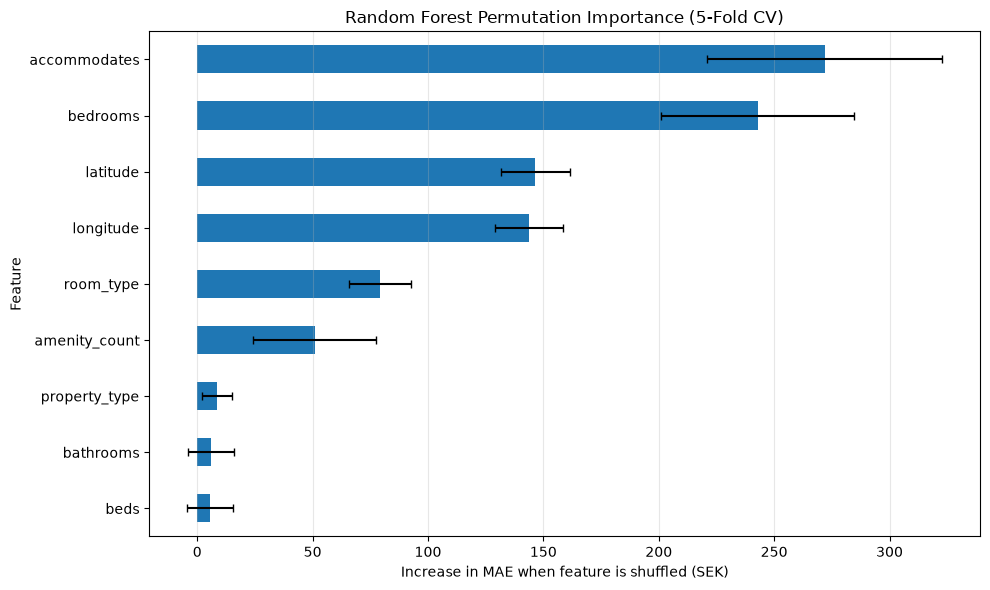

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error

# Use the original Random Forest without individual amenities
cv = KFold(n_splits=5, shuffle=True, random_state=42)

importance_results = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train), start=1):

    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    # Fit a fresh model on each training fold
    model = clone(rf_pipeline)
    model.fit(X_fold_train, y_fold_train)

    # Calculate permutation importance on validation fold
    result = permutation_importance(
        model,
        X_fold_val,
        y_fold_val,
        scoring="neg_mean_absolute_error",
        n_repeats=5,
        random_state=42,
        n_jobs=-1
    )

    importance_results.append(
        pd.DataFrame({
            "feature": X_train.columns,
            "importance": result.importances_mean,
            "fold": fold
        })
    )

# Combine results across folds
importance_df = pd.concat(importance_results)

importance_summary = (
    importance_df
    .groupby("feature")["importance"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
)

print("=== RANDOM FOREST FEATURE IMPORTANCE ===")
print(importance_summary.round(2).to_string())

# Visualization
plt.figure(figsize=(10, 6))

importance_summary["mean"].sort_values().plot(
    kind="barh",
    xerr=importance_summary["std"].sort_values(),
    capsize=3
)

plt.xlabel("Increase in MAE when feature is shuffled (SEK)")
plt.ylabel("Feature")
plt.title("Random Forest Permutation Importance (5-Fold CV)")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate
from sklearn.ensemble import RandomForestRegressor

import mlflow
import numpy as np

# Simplified feature set
selected_numeric_features = [
    "accommodates",
    "bedrooms",
    "latitude",
    "longitude",
    "amenity_count"
]

selected_categorical_features = [
    "room_type"
]

selected_features = (
    selected_numeric_features +
    selected_categorical_features
)

# Reuse existing training data
X_train_selected = X_train[selected_features].copy()

# Simplified preprocessing
selected_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, selected_numeric_features),
        ("cat", categorical_transformer, selected_categorical_features)
    ],
    verbose_feature_names_out=False
)

# Keep Random Forest hyperparameters unchanged
rf_selected_pipeline = Pipeline(steps=[
    ("preprocessor", selected_preprocessor),
    ("model", RandomForestRegressor(**rf_params))
])

# Evaluate using the same five-fold CV setup
with mlflow.start_run(
    run_name="random-forest-selected-features"
) as run:

    cv_results = cross_validate(
        rf_selected_pipeline,
        X_train_selected,
        y_train,
        cv=5,
        scoring=scoring
    )

    cv_mae = -cv_results["test_mae"].mean()
    cv_rmse = -cv_results["test_rmse"].mean()
    cv_r2 = cv_results["test_r2"].mean()

    mlflow.log_params({
        "model": "RandomForestRegressor",
        "feature_set": "selected_6_features",
        "selected_features": ", ".join(selected_features),
        "cv_folds": 5,
        "training_samples": len(X_train_selected),
        "feature_count": len(selected_features),
        **rf_params
    })

    mlflow.log_metrics({
        "cv_mae": cv_mae,
        "cv_rmse": cv_rmse,
        "cv_r2": cv_r2
    })

    print("=== RANDOM FOREST — SELECTED FEATURES ===")
    print(f"Features: {selected_features}")
    print(f"MAE:  {cv_mae:.2f} SEK")
    print(f"RMSE: {cv_rmse:.2f} SEK")
    print(f"R²:   {cv_r2:.4f}")

    print(f"\nMLflow Run ID: {run.info.run_id}")

# Fit the simplified model
rf_selected_pipeline.fit(X_train_selected, y_train)

print("\nSimplified Random Forest fitted successfully.")

=== RANDOM FOREST — SELECTED FEATURES ===
Features: ['accommodates', 'bedrooms', 'latitude', 'longitude', 'amenity_count', 'room_type']
MAE:  782.35 SEK
RMSE: 1503.35 SEK
R²:   0.4882

MLflow Run ID: c946a791c1944fe78b1de3df98b523b7
🏃 View run random-forest-selected-features at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2/runs/c946a791c1944fe78b1de3df98b523b7
🧪 View experiment at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2

Simplified Random Forest fitted successfully.


In [24]:
import numpy as np
import mlflow

from scipy.stats import randint
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

# Define hyperparameter search space
param_distributions = {
    "model__n_estimators": randint(100, 401),
    "model__max_depth": [None, 10, 15, 20, 30],
    "model__min_samples_split": randint(2, 11),
    "model__min_samples_leaf": randint(1, 8),
    "model__max_features": [0.5, 0.75, 1.0]
}

# Build model pipeline
rf_tuning_pipeline = Pipeline(steps=[
    ("preprocessor", selected_preprocessor),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

# Randomized search
random_search = RandomizedSearchCV(
    estimator=rf_tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=20,
    scoring=scoring,
    refit="mae",
    cv=5,
    random_state=42,
    n_jobs=1,
    verbose=1
)

# Track tuning experiment
with mlflow.start_run(
    run_name="random-forest-hyperparameter-tuning"
) as run:

    random_search.fit(X_train_selected, y_train)

    best_index = random_search.best_index_
    results = random_search.cv_results_

    best_mae = -results["mean_test_mae"][best_index]
    best_rmse = -results["mean_test_rmse"][best_index]
    best_r2 = results["mean_test_r2"][best_index]

    mlflow.log_params({
        "model": "RandomForestRegressor",
        "feature_set": "selected_6_features",
        "search_method": "RandomizedSearchCV",
        "n_iter": 20,
        "cv_folds": 5,
        **random_search.best_params_
    })

    mlflow.log_metrics({
        "cv_mae": best_mae,
        "cv_rmse": best_rmse,
        "cv_r2": best_r2
    })

    print("=== BEST HYPERPARAMETERS ===")
    for param, value in random_search.best_params_.items():
        print(f"{param}: {value}")

    print("\n=== BEST RANDOM FOREST RESULTS ===")
    print(f"MAE:  {best_mae:.2f} SEK")
    print(f"RMSE: {best_rmse:.2f} SEK")
    print(f"R²:   {best_r2:.4f}")

    print(f"\nMLflow Run ID: {run.info.run_id}")

# RandomizedSearchCV automatically refits the best pipeline
# on the entire training dataset.
best_rf_pipeline = random_search.best_estimator_

print("\nBest Random Forest model fitted successfully.")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
=== BEST HYPERPARAMETERS ===
model__max_depth: 10
model__max_features: 0.5
model__min_samples_leaf: 1
model__min_samples_split: 7
model__n_estimators: 352

=== BEST RANDOM FOREST RESULTS ===
MAE:  759.30 SEK
RMSE: 1459.93 SEK
R²:   0.5161

MLflow Run ID: d301c472dbbf4ed0acda1de6b4e9db16
🏃 View run random-forest-hyperparameter-tuning at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2/runs/d301c472dbbf4ed0acda1de6b4e9db16
🧪 View experiment at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2

Best Random Forest model fitted successfully.


In [25]:
import numpy as np
import mlflow

from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_validate

# Reuse the best hyperparameters from Step 18
best_rf_params = {
    key.replace("model__", ""): value
    for key, value in random_search.best_params_.items()
}

# Build Random Forest with the tuned parameters
log_rf_pipeline = Pipeline(steps=[
    ("preprocessor", selected_preprocessor),
    ("model", RandomForestRegressor(
        **best_rf_params,
        random_state=42,
        n_jobs=-1
    ))
])

# Apply logarithmic transformation to the target
log_rf_model = TransformedTargetRegressor(
    regressor=log_rf_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

# Track experiment in MLflow
with mlflow.start_run(
    run_name="random-forest-log-target"
) as run:

    cv_results = cross_validate(
        log_rf_model,
        X_train_selected,
        y_train,
        cv=5,
        scoring=scoring
    )

    cv_mae = -cv_results["test_mae"].mean()
    cv_rmse = -cv_results["test_rmse"].mean()
    cv_r2 = cv_results["test_r2"].mean()

    mlflow.log_params({
        "model": "RandomForestRegressor",
        "feature_set": "selected_6_features",
        "target_transformation": "log1p",
        "cv_folds": 5,
        "training_samples": len(X_train_selected),
        **best_rf_params
    })

    mlflow.log_metrics({
        "cv_mae": cv_mae,
        "cv_rmse": cv_rmse,
        "cv_r2": cv_r2
    })

    print("=== RANDOM FOREST WITH LOG TARGET ===")
    print(f"MAE:  {cv_mae:.2f} SEK")
    print(f"RMSE: {cv_rmse:.2f} SEK")
    print(f"R²:   {cv_r2:.4f}")

    print(f"\nMLflow Run ID: {run.info.run_id}")

# Fit on complete training set
log_rf_model.fit(X_train_selected, y_train)

print("\nLog-transformed Random Forest fitted successfully.")

=== RANDOM FOREST WITH LOG TARGET ===
MAE:  717.39 SEK
RMSE: 1479.61 SEK
R²:   0.5087

MLflow Run ID: 438a7e63715547b6a84256a68b0fa118
🏃 View run random-forest-log-target at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2/runs/438a7e63715547b6a84256a68b0fa118
🧪 View experiment at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2

Log-transformed Random Forest fitted successfully.


=== OVERALL OUT-OF-FOLD PERFORMANCE ===
MAE: 723.26 SEK

=== ERRORS BY PRICE GROUP ===
             listings  median_actual_price      mae  median_absolute_error  median_percentage_error
price_group                                                                                        
0–1,000           526               662.00   349.55                 234.57                    36.05
1,000–2,000       824              1449.36   378.42                 279.32                    19.51
2,000–4,000       916              2796.00   664.12                 544.23                    19.77
4,000–8,000       309              4945.10  1598.67                1400.67                    28.09
8,000+             36              9590.25  8067.56                6171.66                    59.64


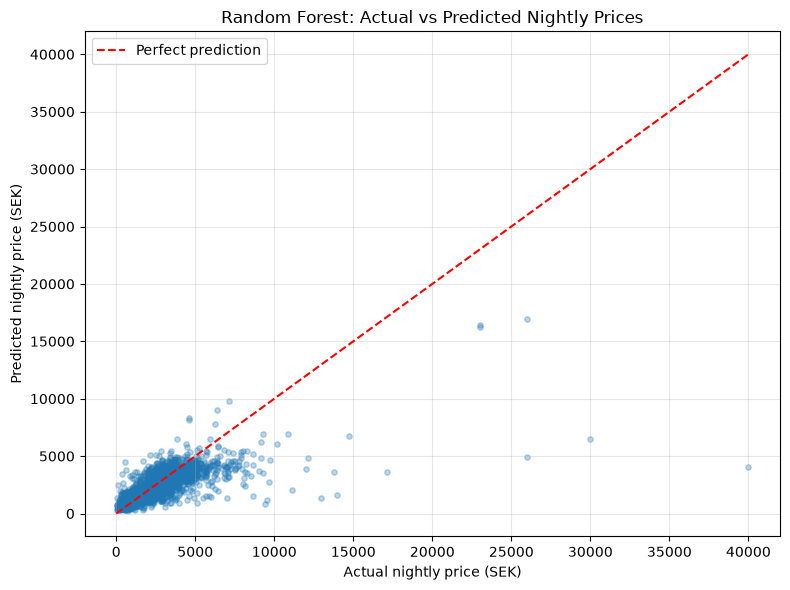

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import cross_val_predict, KFold
from sklearn.metrics import mean_absolute_error

# Use the same fold definition for reproducibility
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Generate out-of-fold predictions
y_pred_cv = cross_val_predict(
    log_rf_model,
    X_train_selected,
    y_train,
    cv=cv,
    n_jobs=1
)

# Create error analysis dataframe
error_df = pd.DataFrame({
    "actual": y_train.to_numpy(),
    "predicted": y_pred_cv
})

error_df["absolute_error"] = abs(
    error_df["actual"] - error_df["predicted"]
)

error_df["percentage_error"] = (
    error_df["absolute_error"] /
    error_df["actual"] * 100
)

# Group listings by actual nightly price
error_df["price_group"] = pd.cut(
    error_df["actual"],
    bins=[0, 1000, 2000, 4000, 8000, np.inf],
    labels=[
        "0–1,000",
        "1,000–2,000",
        "2,000–4,000",
        "4,000–8,000",
        "8,000+"
    ]
)

print("=== OVERALL OUT-OF-FOLD PERFORMANCE ===")
print(f"MAE: {mean_absolute_error(error_df['actual'], error_df['predicted']):.2f} SEK")

print("\n=== ERRORS BY PRICE GROUP ===")

group_summary = (
    error_df
    .groupby("price_group", observed=True)
    .agg(
        listings=("actual", "count"),
        median_actual_price=("actual", "median"),
        mae=("absolute_error", "mean"),
        median_absolute_error=("absolute_error", "median"),
        median_percentage_error=("percentage_error", "median")
    )
    .round(2)
)

print(group_summary.to_string())

# Actual vs predicted visualization
plt.figure(figsize=(8, 6))

plt.scatter(
    error_df["actual"],
    error_df["predicted"],
    alpha=0.3,
    s=15
)

max_price = max(
    error_df["actual"].max(),
    error_df["predicted"].max()
)

plt.plot(
    [0, max_price],
    [0, max_price],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual nightly price (SEK)")
plt.ylabel("Predicted nightly price (SEK)")
plt.title("Random Forest: Actual vs Predicted Nightly Prices")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
# Signed error: positive = overprediction, negative = underprediction
error_df["signed_error"] = (
    error_df["predicted"] - error_df["actual"]
)

# Prediction bias by price group
bias_summary = (
    error_df
    .groupby("price_group", observed=True)
    .agg(
        listings=("actual", "count"),
        mean_actual=("actual", "mean"),
        mean_predicted=("predicted", "mean"),
        mean_signed_error=("signed_error", "mean"),
        median_signed_error=("signed_error", "median")
    )
    .round(2)
)

print("=== PREDICTION BIAS BY PRICE GROUP ===")
print(bias_summary.to_string())

print("\n=== OVERALL PREDICTION BIAS ===")
print(
    f"Mean signed error: "
    f"{error_df['signed_error'].mean():.2f} SEK"
)

print(
    f"Overpredicted listings: "
    f"{(error_df['signed_error'] > 0).mean() * 100:.2f}%"
)

print(
    f"Underpredicted listings: "
    f"{(error_df['signed_error'] < 0).mean() * 100:.2f}%"
)

=== PREDICTION BIAS BY PRICE GROUP ===
             listings  mean_actual  mean_predicted  mean_signed_error  median_signed_error
price_group                                                                               
0–1,000           526       643.17          925.05             281.88               175.88
1,000–2,000       824      1467.80         1608.31             140.52                97.33
2,000–4,000       916      2851.00         2704.64            -146.36              -123.74
4,000–8,000       309      5224.35         3778.12           -1446.22             -1355.96
8,000+             36     13133.97         5066.41           -8067.56             -6171.66

=== OVERALL PREDICTION BIAS ===
Mean signed error: -232.60 SEK
Overpredicted listings: 50.90%
Underpredicted listings: 49.10%


In [28]:
import shap
import numpy as np
import pandas as pd

# Create a consistent mapping for room types
room_categories = sorted(
    X_train_selected["room_type"].dropna().unique()
)

room_to_code = {
    room: i for i, room in enumerate(room_categories)
}

code_to_room = {
    i: room for room, i in room_to_code.items()
}

print("=== ROOM TYPE ENCODING ===")
print(room_to_code)

# Convert room_type to numeric codes for SHAP
def encode_shap_input(df):
    encoded = df.copy()
    encoded["room_type"] = encoded["room_type"].map(room_to_code)
    return encoded.astype(float)

# Convert numeric codes back to the original model inputs
def predict_for_shap(X):
    df = pd.DataFrame(
        X,
        columns=X_train_selected.columns
    )

    # Convert SHAP's numeric representation back to room types
    codes = np.rint(df["room_type"]).astype(int)

    df["room_type"] = [
        code_to_room[code] for code in codes
    ]

    return log_rf_model.predict(df)

# Prepare numeric SHAP samples
background = encode_shap_input(
    shap.sample(X_train_selected, 30, random_state=42)
)

X_explain_original = X_train_selected.sample(
    5,
    random_state=123
)

X_explain = encode_shap_input(X_explain_original)

# Initialize explainer
explainer = shap.Explainer(
    predict_for_shap,
    background,
    algorithm="permutation",
    seed=42
)

# Calculate SHAP explanations
shap_values = explainer(
    X_explain,
    max_evals=200
)

print("\n=== SHAP EXPLANATIONS ===")
print("SHAP values shape:", shap_values.values.shape)

print("\n=== PREDICTION CONSISTENCY CHECK ===")

predictions = log_rf_model.predict(X_explain_original)

reconstructed = (
    shap_values.base_values +
    shap_values.values.sum(axis=1)
)

for i, (pred, reconstructed_pred) in enumerate(
    zip(predictions, reconstructed)
):
    print(
        f"Listing {i + 1}: "
        f"Prediction = {pred:.2f} SEK | "
        f"SHAP reconstruction = {reconstructed_pred:.2f} SEK"
    )

=== ROOM TYPE ENCODING ===
{'Entire home/apt': 0, 'Private room': 1, 'Shared room': 2}

=== SHAP EXPLANATIONS ===
SHAP values shape: (5, 6)

=== PREDICTION CONSISTENCY CHECK ===
Listing 1: Prediction = 2297.64 SEK | SHAP reconstruction = 2297.64 SEK
Listing 2: Prediction = 2589.28 SEK | SHAP reconstruction = 2589.28 SEK
Listing 3: Prediction = 2250.87 SEK | SHAP reconstruction = 2250.87 SEK
Listing 4: Prediction = 2979.32 SEK | SHAP reconstruction = 2979.32 SEK
Listing 5: Prediction = 1073.42 SEK | SHAP reconstruction = 1073.42 SEK


=== LISTING CHARACTERISTICS ===
accommodates                   5
bedrooms                     3.0
latitude               59.281693
longitude               18.10451
amenity_count                9.0
room_type        Entire home/apt

=== PREDICTED NIGHTLY PRICE ===
2,297.64 SEK

=== SHAP CONTRIBUTIONS ===
accommodates     495.12
bedrooms         490.63
room_type         53.64
longitude       -177.51
amenity_count   -221.71
latitude        -381.52


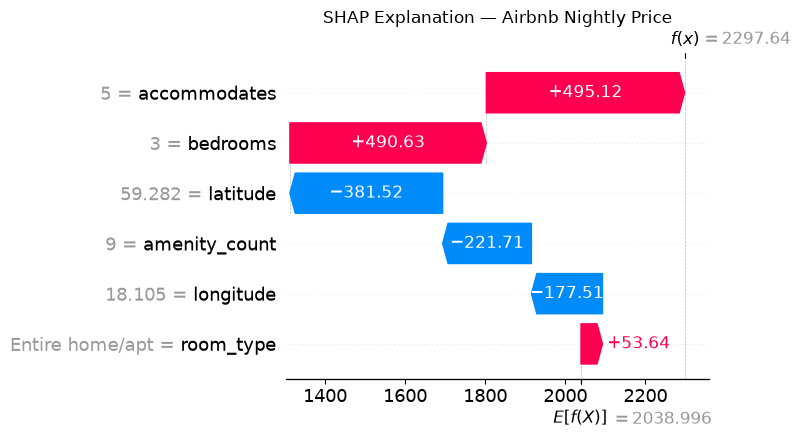

In [29]:
import shap
import matplotlib.pyplot as plt

# Select the first explained listing
listing_index = 0

# Display original listing characteristics
print("=== LISTING CHARACTERISTICS ===")
print(X_explain_original.iloc[listing_index].to_string())

print("\n=== PREDICTED NIGHTLY PRICE ===")
print(f"{predictions[listing_index]:,.2f} SEK")

print("\n=== SHAP CONTRIBUTIONS ===")

contributions = (
    pd.Series(
        shap_values.values[listing_index],
        index=X_explain_original.columns
    )
    .sort_values(ascending=False)
)

print(contributions.round(2).to_string())

# Use the original room-type label in the visualization
plot_explanation = shap.Explanation(
    values=shap_values.values[listing_index],
    base_values=shap_values.base_values[listing_index],
    data=X_explain_original.iloc[listing_index].to_numpy(),
    feature_names=X_explain_original.columns.tolist()
)

# Generate waterfall plot
shap.plots.waterfall(
    plot_explanation,
    max_display=6,
    show=False
)

plt.title("SHAP Explanation — Airbnb Nightly Price")
plt.tight_layout()
plt.show()

PermutationExplainer explainer: 101it [00:59,  1.40it/s]                         

=== GLOBAL SHAP FEATURE IMPORTANCE ===
      feature  mean_abs_shap
 accommodates         423.61
     bedrooms         339.32
     latitude         273.52
    longitude         223.70
    room_type         165.00
amenity_count          90.23


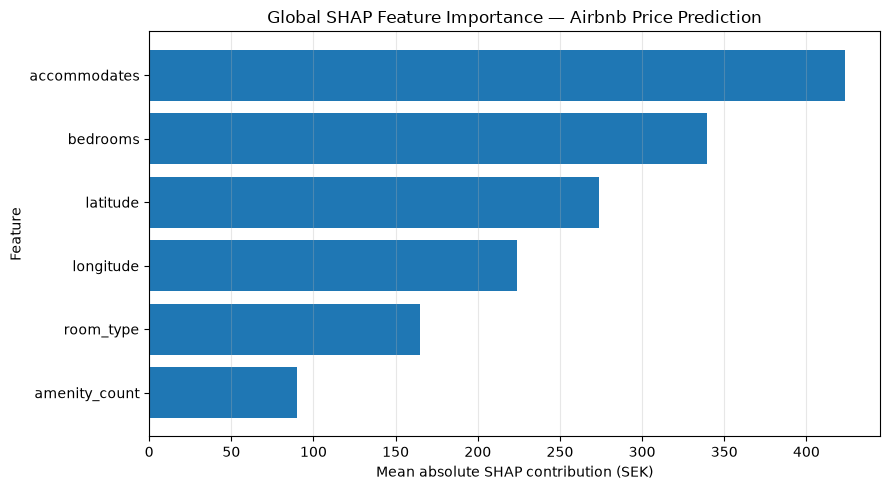

In [30]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Select a reproducible sample for global SHAP analysis
X_global_original = X_train_selected.sample(
    n=100,
    random_state=42
)

# Encode room types for SHAP
X_global = encode_shap_input(X_global_original)

# Calculate SHAP values
global_shap_values = explainer(
    X_global,
    max_evals=100
)

# Calculate mean absolute SHAP contribution
global_importance = pd.DataFrame({
    "feature": X_global_original.columns,
    "mean_abs_shap": np.abs(
        global_shap_values.values
    ).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

print("=== GLOBAL SHAP FEATURE IMPORTANCE ===")
print(global_importance.round(2).to_string(index=False))

# Plot global feature importance
plt.figure(figsize=(9, 5))

plt.barh(
    global_importance["feature"][::-1],
    global_importance["mean_abs_shap"][::-1]
)

plt.xlabel("Mean absolute SHAP contribution (SEK)")
plt.ylabel("Feature")
plt.title("Global SHAP Feature Importance — Airbnb Price Prediction")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Use the same six features as the trained model
X_test_selected = X_test[selected_features].copy()

# Predict prices for the held-out test set
y_test_pred = log_rf_model.predict(X_test_selected)

# Evaluate predictions in SEK
test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)

# Additional diagnostic metrics
test_median_ae = np.median(
    np.abs(y_test.to_numpy() - y_test_pred)
)

test_bias = np.mean(
    y_test_pred - y_test.to_numpy()
)

print("=== FINAL TEST SET EVALUATION ===")
print(f"Test samples: {len(y_test):,}")
print(f"MAE:       {test_mae:.2f} SEK")
print(f"RMSE:      {test_rmse:.2f} SEK")
print(f"R²:        {test_r2:.4f}")
print(f"Median AE: {test_median_ae:.2f} SEK")
print(f"Mean bias: {test_bias:.2f} SEK")

print("\n=== CROSS-VALIDATION VS TEST ===")
print(f"{'Metric':<12} {'CV':>12} {'Test':>12}")
print("-" * 38)
print(f"{'MAE':<12} {717.39:>12.2f} {test_mae:>12.2f}")
print(f"{'RMSE':<12} {1479.61:>12.2f} {test_rmse:>12.2f}")
print(f"{'R²':<12} {0.5087:>12.4f} {test_r2:>12.4f}")

=== FINAL TEST SET EVALUATION ===
Test samples: 653
MAE:       732.69 SEK
RMSE:      1506.07 SEK
R²:        0.4335
Median AE: 389.94 SEK
Mean bias: -278.82 SEK

=== CROSS-VALIDATION VS TEST ===
Metric                 CV         Test
--------------------------------------
MAE                717.39       732.69
RMSE              1479.61      1506.07
R²                 0.5087       0.4335


In [32]:
import mlflow
import mlflow.sklearn

from mlflow.models import infer_signature

# Representative inputs for model signature
input_example = X_train_selected.head(5).copy()

# Generate representative predictions
output_example = log_rf_model.predict(input_example)

# Infer model signature
signature = infer_signature(
    input_example,
    output_example
)

with mlflow.start_run(
    run_name="random-forest-final-model"
) as run:

    # Log model configuration
    mlflow.log_params({
        "model": "RandomForestRegressor",
        "feature_set": "selected_6_features",
        "target_transformation": "log1p",
        "training_samples": len(X_train_selected),
        "test_samples": len(X_test_selected),
        "feature_count": len(selected_features),
        **best_rf_params
    })

    # Log final evaluation metrics
    mlflow.log_metrics({
        "cv_mae": 717.39,
        "cv_rmse": 1479.61,
        "cv_r2": 0.5087,
        "test_mae": test_mae,
        "test_rmse": test_rmse,
        "test_r2": test_r2,
        "test_median_ae": test_median_ae,
        "test_mean_bias": test_bias
    })

    # Log the complete fitted model
    # Explicitly allow the two model types identified by skops
    trusted_types = [
        "numpy.dtype",
        "sklearn.tree._tree.Tree"
    ]

    model_info = mlflow.sklearn.log_model(
        sk_model=log_rf_model,
        name="airbnb_price_model",
        signature=signature,
        input_example=input_example,
        serialization_format="skops",
        skops_trusted_types=trusted_types
    )

    print("=== MODEL LOGGED SUCCESSFULLY ===")
    print("Run ID:", run.info.run_id)
    print("Model URI:", model_info.model_uri)
    print("Input features:", selected_features)

c:\Users\Kim\software engineering\year 5\LP1\4DT911\4dt911-vis-project-research\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


=== MODEL LOGGED SUCCESSFULLY ===
Run ID: be0d72163ad7407790dbd4d4e3f4594b
Model URI: models:/m-6e17a19d9e69474eabb66119791844c7
Input features: ['accommodates', 'bedrooms', 'latitude', 'longitude', 'amenity_count', 'room_type']
🏃 View run random-forest-final-model at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2/runs/be0d72163ad7407790dbd4d4e3f4594b
🧪 View experiment at: https://cu0089.camp.lnu.se/mlflow/#/experiments/2


In [33]:
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd

# Previously saved model
model_uri = "models:/m-dc27602762784e89be366619a944d9c4"

# Load model using its stored skops configuration
loaded_model = mlflow.sklearn.load_model(model_uri)

# Select 10 reproducible training examples
sample_X = X_train_selected.sample(
    n=10,
    random_state=42
)

# Compare original and loaded model predictions
original_predictions = log_rf_model.predict(sample_X)
loaded_predictions = loaded_model.predict(sample_X)

comparison_df = pd.DataFrame({
    "Original prediction": original_predictions,
    "MLflow prediction": loaded_predictions,
    "Difference": np.abs(
        original_predictions - loaded_predictions
    )
})

print("=== MODEL CONSISTENCY CHECK ===")
print(comparison_df.round(6).to_string(index=False))

print("\n=== VERIFICATION ===")
print(
    "Predictions match:",
    np.allclose(
        original_predictions,
        loaded_predictions,
        rtol=1e-10,
        atol=1e-8
    )
)

print(
    "Maximum difference:",
    np.max(np.abs(
        original_predictions - loaded_predictions
    ))
)

=== MODEL CONSISTENCY CHECK ===
 Original prediction  MLflow prediction  Difference
         1452.386949        1452.386949         0.0
         1249.443477        1249.443477         0.0
          926.501120         926.501120         0.0
         2017.368790        2017.368790         0.0
         3332.161875        3332.161875         0.0
         1802.819112        1802.819112         0.0
         4334.986232        4334.986232         0.0
          693.224408         693.224408         0.0
         1800.191310        1800.191310         0.0
         1730.307393        1730.307393         0.0

=== VERIFICATION ===
Predictions match: True
Maximum difference: 7.275957614183426e-12


In [34]:
import mlflow
import numpy as np
import pandas as pd

# Load model with MLflow's inference interface
pyfunc_model = mlflow.pyfunc.load_model(model_uri)

print("=== SAVED MODEL SIGNATURE ===")
print(pyfunc_model.metadata.signature)

print("\n=== INPUT SCHEMA ===")
for col in pyfunc_model.metadata.signature.inputs.inputs:
    print(
        f"{col.name}: "
        f"type={col.type}, "
        f"required={col.required}"
    )

# Create a realistic input example
example_input = pd.DataFrame([{
    "accommodates": 4,
    "bedrooms": np.nan,
    "latitude": 59.3293,
    "longitude": 18.0686,
    "amenity_count": 20.0,
    "room_type": "Entire home/apt"
}])

print("\n=== EXAMPLE INPUT ===")
print(example_input.to_string(index=False))

print("\n=== PYFUNC PREDICTION ===")

try:
    prediction = pyfunc_model.predict(example_input)
    print(f"Predicted nightly price: {prediction[0]:,.2f} SEK")
    print("Input validation successful!")
except Exception as e:
    print("Input validation failed.")
    print(f"Error type: {type(e).__name__}")
    print(f"Error message: {e}")

=== SAVED MODEL SIGNATURE ===
inputs: 
  ['accommodates': long (required), 'bedrooms': double (optional), 'latitude': double (required), 'longitude': double (required), 'amenity_count': double (required), 'room_type': string (required)]
outputs: 
  [Tensor('float64', (-1,))]
params: 
  None


=== INPUT SCHEMA ===
accommodates: type=DataType.long, required=True
bedrooms: type=DataType.double, required=False
latitude: type=DataType.double, required=True
longitude: type=DataType.double, required=True
amenity_count: type=DataType.double, required=True
room_type: type=DataType.string, required=True

=== EXAMPLE INPUT ===
 accommodates  bedrooms  latitude  longitude  amenity_count       room_type
            4       NaN   59.3293    18.0686           20.0 Entire home/apt

=== PYFUNC PREDICTION ===
Predicted nightly price: 1,998.26 SEK
Input validation successful!


In [35]:
import shap
import numpy as np
import pandas as pd

# Use the model loaded from MLflow
def predict_for_shap_mlflow(X):
    df = pd.DataFrame(
        X,
        columns=selected_features
    )

    codes = np.rint(df["room_type"]).astype(int)

    df["room_type"] = [
        code_to_room[code]
        for code in codes
    ]

    return loaded_model.predict(df)


# Create SHAP explainer using the saved model
mlflow_shap_explainer = shap.Explainer(
    predict_for_shap_mlflow,
    background,
    algorithm="permutation",
    seed=42
)


def predict_with_explanation(listing_data):
    """
    Predict nightly price and return SHAP contributions.

    Parameters
    ----------
    listing_data : dict
        Dictionary containing the six input features.

    Returns
    -------
    dict
        Predicted price, baseline and SHAP contributions.
    """

    input_df = pd.DataFrame([listing_data])

    # Generate prediction
    predicted_price = float(
        loaded_model.predict(input_df)[0]
    )

    # Convert categorical features for SHAP
    shap_input = encode_shap_input(input_df)

    # Generate SHAP explanation
    explanation = mlflow_shap_explainer(
        shap_input,
        max_evals=200
    )

    baseline = float(explanation.base_values[0])

    contributions = {
        feature: float(value)
        for feature, value in zip(
            selected_features,
            explanation.values[0]
        )
    }

    return {
        "predicted_price": predicted_price,
        "baseline_price": baseline,
        "shap_values": contributions
    }


# Test using the same example from Step 29
example_listing = {
    "accommodates": 4,
    "bedrooms": np.nan,
    "latitude": 59.3293,
    "longitude": 18.0686,
    "amenity_count": 20.0,
    "room_type": "Entire home/apt"
}

result = predict_with_explanation(example_listing)

print("=== PREDICTION WITH SHAP ===")
print(f"Predicted price: {result['predicted_price']:.2f} SEK")
print(f"Baseline price: {result['baseline_price']:.2f} SEK")

print("\n=== FEATURE CONTRIBUTIONS ===")
for feature, value in result["shap_values"].items():
    print(f"{feature}: {value:+.2f} SEK")

print("\n=== RECONSTRUCTION CHECK ===")
reconstructed = (
    result["baseline_price"] +
    sum(result["shap_values"].values())
)

print(f"Reconstructed price: {reconstructed:.2f} SEK")
print(
    "Matches prediction:",
    np.isclose(
        reconstructed,
        result["predicted_price"],
        atol=1e-5
    )
)

=== PREDICTION WITH SHAP ===
Predicted price: 1998.26 SEK
Baseline price: 2039.00 SEK

=== FEATURE CONTRIBUTIONS ===
accommodates: +158.83 SEK
bedrooms: -698.34 SEK
latitude: +255.73 SEK
longitude: +254.49 SEK
amenity_count: -59.28 SEK
room_type: +47.73 SEK

=== RECONSTRUCTION CHECK ===
Reconstructed price: 1998.15 SEK
Matches prediction: False


In [36]:
import numpy as np
import pandas as pd

def check_shap_consistency(listing_data):
    input_df = pd.DataFrame(
        [listing_data],
        columns=selected_features
    )

    shap_input = encode_shap_input(input_df)

    # Direct prediction
    direct_prediction = float(
        loaded_model.predict(input_df)[0]
    )

    # Prediction through SHAP wrapper
    wrapper_prediction = float(
        predict_for_shap_mlflow(shap_input)[0]
    )

    # SHAP explanation
    explanation = mlflow_shap_explainer(
        shap_input,
        max_evals=200
    )

    reconstructed = float(
        explanation.base_values[0] +
        explanation.values[0].sum()
    )

    print("Direct prediction: ", direct_prediction)
    print("Wrapper prediction:", wrapper_prediction)
    print("SHAP reconstructed:", reconstructed)

    print("\nDifferences:")
    print(
        "Direct vs wrapper:",
        abs(direct_prediction - wrapper_prediction)
    )
    print(
        "Wrapper vs SHAP:",
        abs(wrapper_prediction - reconstructed)
    )


print("=== LISTING WITH MISSING BEDROOMS ===")
check_shap_consistency(example_listing)

print("\n=== LISTING WITHOUT MISSING BEDROOMS ===")

complete_listing = example_listing.copy()
complete_listing["bedrooms"] = 2.0

check_shap_consistency(complete_listing)

=== LISTING WITH MISSING BEDROOMS ===
Direct prediction:  1998.2599572068596
Wrapper prediction: 1998.2599572068577
SHAP reconstructed: 1998.1760706926789

Differences:
Direct vs wrapper: 1.8189894035458565e-12
Wrapper vs SHAP: 0.0838865141788574

=== LISTING WITHOUT MISSING BEDROOMS ===
Direct prediction:  3503.7718890367405
Wrapper prediction: 3503.7718890367405
SHAP reconstructed: 3503.7747791616675

Differences:
Direct vs wrapper: 0.0
Wrapper vs SHAP: 0.002890124927034776


In [37]:
import shap
import numpy as np
import pandas as pd

MISSING_SENTINEL = -999.0

# Encode model inputs for SHAP
def encode_shap_input_v2(df):
    encoded = df.copy()

    encoded["room_type"] = encoded["room_type"].map(room_to_code)

    encoded["bedrooms"] = encoded["bedrooms"].fillna(
        MISSING_SENTINEL
    )

    return encoded.astype(float)


# Prediction wrapper that restores the original input values
def predict_for_shap_v2(X):
    df = pd.DataFrame(
        X,
        columns=selected_features
    ).copy()

    # Restore missing bedrooms
    df["bedrooms"] = df["bedrooms"].replace(
        MISSING_SENTINEL,
        np.nan
    )

    # Restore categorical room types
    codes = np.rint(df["room_type"]).astype(int)

    df["room_type"] = [
        code_to_room[code] for code in codes
    ]

    return loaded_model.predict(df)


# Prepare background data using the new encoding
background_v2 = encode_shap_input_v2(
    shap.sample(X_train_selected, 30, random_state=42)
)

# Create new SHAP explainer
explainer_v2 = shap.Explainer(
    predict_for_shap_v2,
    background_v2,
    algorithm="permutation",
    seed=42
)


# Test both examples
for name, listing in [
    ("Missing bedrooms", example_listing),
    ("Complete bedrooms", complete_listing)
]:

    input_df = pd.DataFrame(
        [listing],
        columns=selected_features
    )

    shap_input = encode_shap_input_v2(input_df)

    direct_prediction = float(
        loaded_model.predict(input_df)[0]
    )

    wrapper_prediction = float(
        predict_for_shap_v2(shap_input)[0]
    )

    explanation = explainer_v2(
        shap_input,
        max_evals=200
    )

    reconstructed = float(
        explanation.base_values[0] +
        explanation.values[0].sum()
    )

    print(f"\n=== {name.upper()} ===")
    print(f"Direct prediction:  {direct_prediction:.10f}")
    print(f"Wrapper prediction: {wrapper_prediction:.10f}")
    print(f"SHAP reconstruction: {reconstructed:.10f}")

    print(
        "Absolute difference:",
        abs(wrapper_prediction - reconstructed)
    )

    print(
        "Reconstruction matches:",
        np.isclose(
            direct_prediction,
            reconstructed,
            rtol=0,
            atol=1e-5
        )
    )


=== MISSING BEDROOMS ===
Direct prediction:  1998.2599572069
Wrapper prediction: 1998.2599572069
SHAP reconstruction: 1998.1481085213
Absolute difference: 0.11184868557029404
Reconstruction matches: False

=== COMPLETE BEDROOMS ===
Direct prediction:  3503.7718890367
Wrapper prediction: 3503.7718890367
SHAP reconstruction: 3503.7805594115
Absolute difference: 0.008670374791563518
Reconstruction matches: False


In [38]:
import numpy as np
import pandas as pd

def test_batch_consistency(listing, name):
    input_df = pd.DataFrame(
        [listing],
        columns=selected_features
    )

    shap_input = encode_shap_input(input_df)

    # Same listing repeated in different-sized batches
    batch_sizes = [1, 10, 30, 100, 500]

    print(f"\n=== {name.upper()} ===")

    reference = float(
        loaded_model.predict(input_df)[0]
    )

    print(f"Reference prediction: {reference:.10f} SEK")

    for batch_size in batch_sizes:
        repeated = pd.concat(
            [shap_input] * batch_size,
            ignore_index=True
        )

        batch_predictions = np.asarray(
            predict_for_shap_mlflow(repeated)
        )

        max_difference = np.max(
            np.abs(batch_predictions - reference)
        )

        print(
            f"Batch size {batch_size:>3}: "
            f"first={batch_predictions[0]:.10f}, "
            f"max difference={max_difference:.10f} SEK"
        )

test_batch_consistency(
    example_listing,
    "Missing bedrooms"
)

test_batch_consistency(
    complete_listing,
    "Complete bedrooms"
)


=== MISSING BEDROOMS ===
Reference prediction: 1998.2599572069 SEK
Batch size   1: first=1998.2599572069, max difference=0.0000000000 SEK
Batch size  10: first=1998.2599572069, max difference=0.0000000000 SEK
Batch size  30: first=1998.2599572069, max difference=0.0000000000 SEK
Batch size 100: first=1998.2599572069, max difference=0.0000000000 SEK
Batch size 500: first=1998.2599572069, max difference=0.0000000000 SEK

=== COMPLETE BEDROOMS ===
Reference prediction: 3503.7718890367 SEK
Batch size   1: first=3503.7718890367, max difference=0.0000000000 SEK
Batch size  10: first=3503.7718890368, max difference=0.0000000000 SEK
Batch size  30: first=3503.7718890367, max difference=0.0000000000 SEK
Batch size 100: first=3503.7718890367, max difference=0.0000000000 SEK
Batch size 500: first=3503.7718890367, max difference=0.0000000000 SEK


In [39]:
import numpy as np
import pandas as pd

# Use the original explainer, without the sentinel workaround
input_df = pd.DataFrame(
    [example_listing],
    columns=selected_features
)

shap_input = encode_shap_input(input_df)

actual_prediction = float(
    loaded_model.predict(input_df)[0]
)

print("=== SHAP RECONSTRUCTION BY EVALUATION BUDGET ===")
print(f"Model prediction: {actual_prediction:.10f} SEK\n")

for max_evals in [100, 300, 600]:
    explanation = mlflow_shap_explainer(
        shap_input,
        max_evals=max_evals
    )

    reconstructed = float(
        explanation.base_values[0] +
        explanation.values[0].sum()
    )

    difference = abs(actual_prediction - reconstructed)

    print(
        f"max_evals={max_evals:>3} | "
        f"reconstructed={reconstructed:.10f} | "
        f"difference={difference:.10f} SEK"
    )

=== SHAP RECONSTRUCTION BY EVALUATION BUDGET ===
Model prediction: 1998.2599572069 SEK

max_evals=100 | reconstructed=1998.2000382682 | difference=0.0599189387 SEK
max_evals=300 | reconstructed=1998.2417210081 | difference=0.0182361987 SEK
max_evals=600 | reconstructed=1998.1505400145 | difference=0.1094171924 SEK


In [40]:

import json
from pathlib import Path

# Store explanation configuration in the research project
shap_dir = Path("../../models/airbnb_price_prediction")
shap_dir.mkdir(parents=True, exist_ok=True)

# Save the exact background used by our working SHAP explainer
background.to_csv(
    shap_dir / "shap_background.csv",
    index=False
)

# Save feature names and categorical encoding
shap_config = {
    "model_uri": model_uri,
    "feature_names": selected_features,
    "room_to_code": room_to_code,
    "shap_algorithm": "permutation",
    "shap_max_evals": 200
}

with open(
    shap_dir / "shap_config.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(shap_config, f, indent=4)

print("=== SHAP CONFIGURATION SAVED ===")
print("Directory:", shap_dir.resolve())

print("\nSaved files:")
for file in shap_dir.iterdir():
    print(f"- {file.name}")

print("\nBackground shape:", background.shape)
print("Feature names:", selected_features)
print("Room type mapping:", room_to_code)


=== SHAP CONFIGURATION SAVED ===
Directory: C:\Users\Kim\software engineering\year 5\LP1\4DT911\4dt911-vis-project-research\models\airbnb_price_prediction

Saved files:
- shap_background.csv
- shap_config.json

Background shape: (30, 6)
Feature names: ['accommodates', 'bedrooms', 'latitude', 'longitude', 'amenity_count', 'room_type']
Room type mapping: {'Entire home/apt': 0, 'Private room': 1, 'Shared room': 2}
